# Own Synthetic — SDQT vs. k (mean ± std over seeds)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS = Path("../../results")
CONDITIONS = ["gaussian", "baseline", "amplitude_mod"]
METHOD_COLORS = {"neurokit": "tab:blue", "i2dsw": "tab:orange"}
FILTER_STYLES = {"own": "-", "orini": "--"}
N_BEATS_CFG = 15  # own synthetic set also contains other n_beats configs;
                  # filter explicitly, do not rely on the filename

In [2]:
df = pd.read_csv(RESULTS / "synthetic_v2.csv")

SEEDS = list(range(67, 77))  # all 10 seeds (67-76)

df = df[
    (df.status == "ok") &
    (df.n_beats_cfg == N_BEATS_CFG) &
    (df.seed.isin(SEEDS))
].copy()

df["k"] = df["k"].astype(float)
print(f"{df.seed.nunique()} seeds per (k, condition, method, filter_cfg)")
df.head()

10 seeds per (k, condition, method, filter_cfg)


,seed,k,condition,method,filter_cfg,n_beats_cfg,sdqt,sdrt,qtvi,n_beats,n_rejected,n_t_amp_nan,n_iso_fallback,n_failed,threshold_uv,n_kept,n_total,elapsed_s,status,error
0,67,0.1,clean,neurokit,own,15,2.871165,7.841843,NaN,13,1,0,0,1,NaN,NaN,14,0.1,ok,NaN
1,67,0.1,clean,neurokit,orini,15,6.265494,3.347953,NaN,13,1,0,0,1,NaN,NaN,14,0.1,ok,NaN
2,67,0.1,gaussian,neurokit,own,15,46.746217,7.687938,NaN,14,0,0,0,0,NaN,NaN,14,0.1,ok,NaN
3,67,0.1,gaussian,neurokit,orini,15,26.955091,5.837074,NaN,13,1,0,0,1,NaN,NaN,14,0.1,ok,NaN
4,67,0.1,baseline,neurokit,own,15,5.314470,3.738229,NaN,13,1,1,0,1,NaN,NaN,14,0.1,ok,NaN


In [3]:
# aggregate across seeds: mean and std of SDQT per (k, condition, method, filter_cfg)
agg = (df.groupby(["k", "condition", "method", "filter_cfg"])["sdqt"]
         .agg(["mean", "std", "count"])
         .reset_index()
         .sort_values(["k", "condition", "method", "filter_cfg"]))
agg.head()

,k,condition,method,filter_cfg,mean,std,count
0,0.1,amplitude_mod,i2dsw,orini,9.939508,1.753735,10
1,0.1,amplitude_mod,i2dsw,own,9.237891,1.156500,10
2,0.1,amplitude_mod,neurokit,orini,23.552547,3.774315,10
3,0.1,amplitude_mod,neurokit,own,33.839419,1.428505,10
4,0.1,baseline,i2dsw,orini,3.586284,0.944763,10


saved own_synthetic_sdqt_vs_k.pdf / .png -> ../../figures


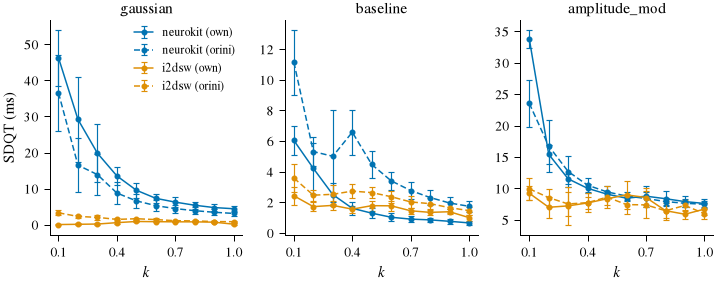

In [4]:
# Plot SDQT vs k for each condition across all methods and filter configs
import sys
sys.path.insert(0, "../..")
from src.tests.style import set_thesis_style, save, TEXT_WIDTH_IN, BLUE, ORANGE

set_thesis_style(use_tex=False)



METHOD_COLORS = {"neurokit": BLUE, "i2dsw": ORANGE}
FILTER_STYLES = {"own": "-", "orini": (0, (4, 2))}

fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(TEXT_WIDTH_IN, 2.6),
                          sharey=False)

for i, condition in enumerate(CONDITIONS):
    ax = axes[i]
    cond_data = agg[agg["condition"] == condition]

    for method, color in METHOD_COLORS.items():
        for f_cfg, style in FILTER_STYLES.items():
            subset = cond_data[(cond_data["method"] == method) & (cond_data["filter_cfg"] == f_cfg)]
            if subset.empty:
                continue
            ax.errorbar(
                subset["k"], subset["mean"], yerr=subset["std"],
                label=f"{method} ({f_cfg})", color=color, ls=style,
                marker="o", ms=2.6, lw=0.9, capsize=2, capthick=0.7, elinewidth=0.7,
            )

    ax.set_title(condition, pad=4)
    ax.set_xlabel("$k$")
    ax.set_xticks([0.1, 0.4, 0.7, 1.0])
    ax.tick_params(labelleft=True)

axes[0].set_ylabel("SDQT (ms)")
axes[0].legend(loc="upper right", fontsize=7, handlelength=1.6, borderaxespad=0.2)

fig.tight_layout()
out_dir = Path("../../figures")
save(fig, "own_synthetic_sdqt_vs_k", out_dir)
plt.show()

In [5]:
# Min/max SDQT over the 10 k-values, per condition, for i2dsw+own filter
_conditions = ["clean", "gaussian", "baseline", "amplitude_mod"]
subset = agg[(agg["method"] == "i2dsw") & (agg["filter_cfg"] == "own")]

for condition in _conditions:
    cond_data = subset[subset["condition"] == condition]["mean"]
    print(f"{condition}: min={cond_data.min():.3f}  max={cond_data.max():.3f}")


clean: min=0.440  max=1.786
gaussian: min=0.024  max=0.876
baseline: min=1.000  max=2.427
amplitude_mod: min=5.892  max=9.238


In [6]:
# Average SDQT over all k-values and all 10 seeds, per condition, for own vs orini filter (i2dsw only)
i2dsw_df = df[(df["method"] == "i2dsw") & (df["filter_cfg"].isin(["own", "orini"]))]

per_cond = i2dsw_df.groupby(["condition", "filter_cfg"])["sdqt"].mean()
for condition in _conditions:
    for filter_cfg in ["own", "orini"]:
        print(f"{condition} / {filter_cfg}: {per_cond.loc[(condition, filter_cfg)]:.3f}")

# Overall average over everything (all conditions, ks, seeds), per filter config
overall = i2dsw_df.groupby("filter_cfg")["sdqt"].mean()
print()
for filter_cfg in ["own", "orini"]:
    print(f"overall / {filter_cfg}: {overall.loc[filter_cfg]:.3f}")


clean / own: 0.939
clean / orini: 1.555
gaussian / own: 0.489
gaussian / orini: 1.586
baseline / own: 1.623
baseline / orini: 2.335
amplitude_mod / own: 7.612
amplitude_mod / orini: 7.690

overall / own: 2.666
overall / orini: 3.291


In [7]:
# Mean SDQT per condition, method, and filter configuration
_methods = ["neurokit", "i2dsw"]

table_df = df[df["filter_cfg"].isin(["own", "orini"])]
table = (
    table_df.groupby(["condition", "method", "filter_cfg"])["sdqt"]
    .mean()
    .unstack("filter_cfg")[["own", "orini"]]
    .reindex(pd.MultiIndex.from_product([_conditions, _methods], names=["condition", "method"]))
)

for condition in _conditions:
    for method in _methods:
        own, orini = table.loc[(condition, method)]
        print(f"{condition} / {method}: own={own:.3f}  orini={orini:.3f}")


clean / neurokit: own=1.599  orini=3.247
clean / i2dsw: own=0.939  orini=1.555
gaussian / neurokit: own=14.635  orini=10.237
gaussian / i2dsw: own=0.489  orini=1.586
baseline / neurokit: own=1.986  orini=4.470
baseline / i2dsw: own=1.623  orini=2.335
amplitude_mod / neurokit: own=12.099  orini=11.317
amplitude_mod / i2dsw: own=7.612  orini=7.690


In [8]:
from scipy.stats import wilcoxon

CONDITIONS = ["clean", "gaussian", "baseline", "amplitude_mod"]
METHODS = ["i2dsw"]  # e.g. ["i2dsw"] or ["i2dsw", "neurokit"]
FILTERS = ["own", "orini"]

df_full = pd.read_csv(RESULTS / "synthetic_v2.csv")
df_full = df_full[df_full.status == "ok"].copy()

results = []
for method in METHODS:
    for filter_cfg in FILTERS:
        for condition in CONDITIONS:
            d15 = df_full[(df_full.n_beats_cfg == 15) & (df_full.method == method) &
                     (df_full.filter_cfg == filter_cfg) & (df_full.condition == condition)]
            d120 = df_full[(df_full.n_beats_cfg == 120) & (df_full.method == method) &
                      (df_full.filter_cfg == filter_cfg) & (df_full.condition == condition)]

            # pair on k only, restricted to the seed(s) present in both
            common_seeds = sorted(set(d15.seed) & set(d120.seed))
            d15p = d15[d15.seed.isin(common_seeds)].sort_values(["seed", "k"])
            d120p = d120[d120.seed.isin(common_seeds)].sort_values(["seed", "k"])

            assert len(d15p) == len(d120p), f"unpaired mismatch for {method}/{filter_cfg}/{condition}"

            stat, p = wilcoxon(d15p.sdqt.values, d120p.sdqt.values)
            results.append({
                "method": method, "filter_cfg": filter_cfg, "condition": condition,
                "n_pairs": len(d15p), "n_seeds": len(common_seeds),
                "median_15s": d15p.sdqt.median(), "median_120s": d120p.sdqt.median(),
                "wilcoxon_stat": stat, "p_value": p,
            })

pd.DataFrame(results)

,method,filter_cfg,condition,n_pairs,n_seeds,median_15s,median_120s,wilcoxon_stat,p_value
0,i2dsw,own,clean,10,1,0.949522,0.314521,0.0,0.001953
1,i2dsw,own,gaussian,10,1,0.940796,0.479368,10.0,0.083984
2,i2dsw,own,baseline,10,1,1.705222,1.278129,0.0,0.001953
3,i2dsw,own,amplitude_mod,10,1,7.205457,6.003198,10.0,0.083984
4,i2dsw,orini,clean,10,1,1.512899,0.463480,0.0,0.001953
5,i2dsw,orini,gaussian,10,1,0.972033,0.540539,0.0,0.001953
6,i2dsw,orini,baseline,10,1,2.055835,1.629987,13.0,0.160156
7,i2dsw,orini,amplitude_mod,10,1,7.463435,6.698281,21.0,0.556641


In [9]:
# Spearman correlation between 15s and 120s SDQT, own filter, both methods (same pairs as the Wilcoxon test above)
from scipy.stats import spearmanr

SPEARMAN_METHODS = ["i2dsw", "neurokit"]
SPEARMAN_FILTERS = ["own"]

spearman_results = []
for method in SPEARMAN_METHODS:
    for filter_cfg in SPEARMAN_FILTERS:
        for condition in CONDITIONS:
            d15 = df_full[(df_full.n_beats_cfg == 15) & (df_full.method == method) &
                     (df_full.filter_cfg == filter_cfg) & (df_full.condition == condition)]
            d120 = df_full[(df_full.n_beats_cfg == 120) & (df_full.method == method) &
                      (df_full.filter_cfg == filter_cfg) & (df_full.condition == condition)]

            common_seeds = sorted(set(d15.seed) & set(d120.seed))
            d15p = d15[d15.seed.isin(common_seeds)].sort_values(["seed", "k"])
            d120p = d120[d120.seed.isin(common_seeds)].sort_values(["seed", "k"])

            assert len(d15p) == len(d120p), f"unpaired mismatch for {method}/{filter_cfg}/{condition}"

            rho, p = spearmanr(d15p.sdqt.values, d120p.sdqt.values)
            spearman_results.append({
                "method": method, "filter_cfg": filter_cfg, "condition": condition,
                "n_pairs": len(d15p), "n_seeds": len(common_seeds),
                "spearman_rho": rho, "p_value": p,
            })

pd.DataFrame(spearman_results)

,method,filter_cfg,condition,n_pairs,n_seeds,spearman_rho,p_value
0,i2dsw,own,clean,10,1,0.854545,1.636803e-03
1,i2dsw,own,gaussian,10,1,0.769697,9.221953e-03
2,i2dsw,own,baseline,10,1,0.939394,5.484053e-05
3,i2dsw,own,amplitude_mod,10,1,0.830303,2.940227e-03
4,neurokit,own,clean,10,1,0.987879,9.307460e-08
5,neurokit,own,gaussian,10,1,1.000000,6.646897e-64
6,neurokit,own,baseline,10,1,0.996965,3.698093e-10
7,neurokit,own,amplitude_mod,10,1,1.000000,6.646897e-64


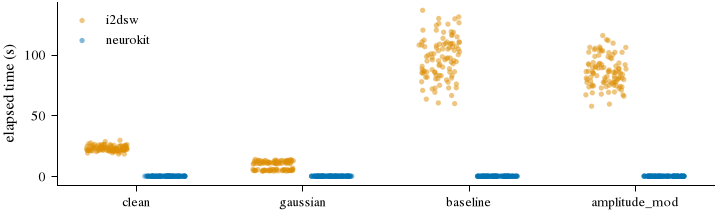

In [10]:
# Runtime (elapsed_s) jittered scatter for the 15s data, own filter, per condition and method
_runtime_df = df[df["filter_cfg"] == "own"]
_runtime_methods = ["i2dsw", "neurokit"]
_runtime_colors = {"i2dsw": ORANGE, "neurokit": BLUE}

plt.rcdefaults()
set_thesis_style(use_tex=False)

fig, ax = plt.subplots(figsize=(TEXT_WIDTH_IN, 2))

width = 0.35
positions = np.arange(len(_conditions))
rng = np.random.default_rng(0)

for j, method in enumerate(_runtime_methods):
    offset = (j - 0.5) * width
    for i, c in enumerate(_conditions):
        vals = _runtime_df[(_runtime_df["condition"] == c) & (_runtime_df["method"] == method)]["elapsed_s"]
        jitter = rng.uniform(-width * 0.35, width * 0.35, size=len(vals))
        ax.scatter(
            positions[i] + offset + jitter,
            vals,
            color=_runtime_colors[method],
            alpha=0.5,
            s=10,
            edgecolors="none",
            label=method if i == 0 else None,
        )

ax.set_xticks(positions)
ax.set_xticklabels(_conditions)
ax.set_ylabel("elapsed time (s)")
ax.legend()
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(out_dir / f"own_synthetic_runtime.{ext}")
plt.show()


In [11]:
# Average runtime (elapsed_s), own filter, i2dsw vs neurokit
_runtime_avg = df[df["filter_cfg"] == "own"].groupby("method")["elapsed_s"].mean()

for method in ["i2dsw", "neurokit"]:
    print(f"{method}: {_runtime_avg.loc[method]:.3f} s")


i2dsw: 53.718 s
neurokit: 0.077 s


In [12]:
# Mean beat-funnel counters per condition and method, own filter, over all k-values and seeds
_cols = ["n_total", "n_failed", "n_rejected", "n_beats", "n_iso_fallback", "n_t_amp_nan"]
_condition_order = ["clean", "gaussian", "baseline", "amplitude_mod"]

_counters_df = pd.read_csv(RESULTS / "synthetic_v2.csv")
_counters_df = _counters_df[(_counters_df["filter_cfg"] == "own") & (_counters_df["status"] == "ok") & (_counters_df["n_beats_cfg"] == 15)]

counters_table = (
    _counters_df.groupby(["condition", "method"])[_cols]
    .mean()
    .reindex(_condition_order, level="condition")
)
counters_table


n_total  n_failed  n_rejected  n_beats  \
condition     method                                             
clean         i2dsw        13.0      0.00        0.00    13.00   
              neurokit     14.0      0.10        0.10    13.90   
gaussian      i2dsw        13.0      0.00        0.01    12.99   
              neurokit     14.0      0.00        0.37    13.63   
baseline      i2dsw        13.0      0.00        0.01    12.99   
              neurokit     14.0      0.13        0.13    13.87   
amplitude_mod i2dsw        13.0      0.00        0.02    12.98   
              neurokit     14.0      0.54        1.62    12.38   

                        n_iso_fallback  n_t_amp_nan  
condition     method                                 
clean         i2dsw                0.0         0.00  
              neurokit             0.0         0.00  
gaussian      i2dsw                0.0         0.00  
              neurokit             0.0         0.35  
baseline      i2dsw                0.0         0.00  
              neurokit             0.0         0.07  
amplitude_mod i2dsw                0.0         0.00  
              neurokit             0.0         1.26

In [13]:
# Mean SDRT - SDQT per method and filter_cfg, over all conditions/k/seeds (15 s only)
df["rt_qt_diff"] = df["sdrt"] - df["sdqt"]
summary = df.groupby(["method", "filter_cfg"])[["sdqt", "sdrt", "rt_qt_diff"]].mean()
summary


sdqt      sdrt  rt_qt_diff
method   filter_cfg                                
i2dsw    orini       3.291440  2.048484   -1.242956
         own         2.665691  1.774840   -0.890851
neurokit orini       7.317721  2.118739   -5.198982
         own         7.579839  2.977292   -4.602547